# SVM (Support Vector Machine)
---

* Separando con hiperplanos (recta en el plano)
* Separar los casos en 2 clases 
* Es supervisado, se conoce la clase
* Se busca la recta cuya mínima distancia sea máxima, es decir, que separe BIEN
* Se elige el de mayor margen de separación: el maximal margin hyperplane

## Support Vector Classifier

* Hiperplano que "casi" separe las clases, pero permitiendo que cometa unos pocos errores
* Se ajuta con un hiperparámetro de tuning C
    * C es grande se penaliza mucho (0 error)
    * C es chico se penaliza poco   

![SVM](img/svm.png)

* Cuando es casi imposible separar en el plano mediante recta, entonces se hace una transformación a un espacio (se agrega una dimensión mayor). Y es alli es donde se hace la separación
* Esto se logra mediante kernels (aplicando una función)

## SVM kernels

![SVM Kernels](img/svm-kernels.png)

## Ejemplo

In [19]:
library(readxl)
library(ggplot2)
library(dplyr)
library(caret)
library(ROCR)
library(e1071)
library(ISLR)

In [20]:
data(Smarket)
mercados <- Smarket # porcentajes diarios de rendimiento para el índice bursátil S&P 500 entre el 2001 y 2005

In [21]:
head(mercados)

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today,Direction
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,2001,0.381,-0.192,-2.624,-1.055,5.010,1.1913,0.959,Up
2,2001,0.959,0.381,-0.192,-2.624,-1.055,1.2965,1.032,Up
3,2001,1.032,0.959,0.381,-0.192,-2.624,1.4112,-0.623,Down
4,2001,-0.623,1.032,0.959,0.381,-0.192,1.2760,0.614,Up
5,2001,0.614,-0.623,1.032,0.959,0.381,1.2057,0.213,Up
6,2001,0.213,0.614,-0.623,1.032,0.959,1.3491,1.392,Up


In [22]:
summary(mercados)

      Year           Lag1                Lag2                Lag3          
 Min.   :2001   Min.   :-4.922000   Min.   :-4.922000   Min.   :-4.922000  
 1st Qu.:2002   1st Qu.:-0.639500   1st Qu.:-0.639500   1st Qu.:-0.640000  
 Median :2003   Median : 0.039000   Median : 0.039000   Median : 0.038500  
 Mean   :2003   Mean   : 0.003834   Mean   : 0.003919   Mean   : 0.001716  
 3rd Qu.:2004   3rd Qu.: 0.596750   3rd Qu.: 0.596750   3rd Qu.: 0.596750  
 Max.   :2005   Max.   : 5.733000   Max.   : 5.733000   Max.   : 5.733000  
      Lag4                Lag5              Volume           Today          
 Min.   :-4.922000   Min.   :-4.92200   Min.   :0.3561   Min.   :-4.922000  
 1st Qu.:-0.640000   1st Qu.:-0.64000   1st Qu.:1.2574   1st Qu.:-0.639500  
 Median : 0.038500   Median : 0.03850   Median :1.4229   Median : 0.038500  
 Mean   : 0.001636   Mean   : 0.00561   Mean   :1.4783   Mean   : 0.003138  
 3rd Qu.: 0.596750   3rd Qu.: 0.59700   3rd Qu.:1.6417   3rd Qu.: 0.596750  
 Max. 

In [23]:
str(mercados) 
# ver que la variable objetivo esté como factor y también las cualis!
# las variables se escalan internamente, lo hace la función svm()

'data.frame':	1250 obs. of  9 variables:
 $ Year     : num  2001 2001 2001 2001 2001 ...
 $ Lag1     : num  0.381 0.959 1.032 -0.623 0.614 ...
 $ Lag2     : num  -0.192 0.381 0.959 1.032 -0.623 ...
 $ Lag3     : num  -2.624 -0.192 0.381 0.959 1.032 ...
 $ Lag4     : num  -1.055 -2.624 -0.192 0.381 0.959 ...
 $ Lag5     : num  5.01 -1.055 -2.624 -0.192 0.381 ...
 $ Volume   : num  1.19 1.3 1.41 1.28 1.21 ...
 $ Today    : num  0.959 1.032 -0.623 0.614 0.213 ...
 $ Direction: Factor w/ 2 levels "Down","Up": 2 2 1 2 2 2 1 2 2 2 ...


In [24]:
# se crea entrenamiento y test
set.seed(123)
index <- createDataPartition(y = mercados$Direction, p = 0.75, list = FALSE)
entreno <- mercados[index,]
testeo <- mercados[-index,]

In [25]:
model.svm0 <- svm(Direction ~ ., kernel = "linear", data = entreno) # default cost = 1
model.svm0


Call:
svm(formula = Direction ~ ., data = entreno, kernel = "linear")


Parameters:
   SVM-Type:  C-classification 
 SVM-Kernel:  linear 
       cost:  1 

Number of Support Vectors:  132


In [26]:
model.svm1 <- svm(Direction ~ ., kernel = "radial", cost = 10, data = entreno)
model.svm1
summary(model.svm1)


Call:
svm(formula = Direction ~ ., data = entreno, kernel = "radial", cost = 10)


Parameters:
   SVM-Type:  C-classification 
 SVM-Kernel:  radial 
       cost:  10 

Number of Support Vectors:  214



Call:
svm(formula = Direction ~ ., data = entreno, kernel = "radial", cost = 10)


Parameters:
   SVM-Type:  C-classification 
 SVM-Kernel:  radial 
       cost:  10 

Number of Support Vectors:  214

 ( 105 109 )


Number of Classes:  2 

Levels: 
 Down Up




In [27]:
# Predicción en test:
pred.svm0<-predict(model.svm1,testeo,type="class")# "class o response dan la clase predicha
pred.svm1<-predict(model.svm1,testeo,type="response")

In [28]:
tabla.svm0<-table(pred.svm0,testeo$Direction) 
confusion.svm0 <- confusionMatrix(tabla.svm0,positive = "Up")
confusion.svm0

Confusion Matrix and Statistics

         
pred.svm0 Down  Up
     Down  147   7
     Up      3 155
                                          
               Accuracy : 0.9679          
                 95% CI : (0.9418, 0.9845)
    No Information Rate : 0.5192          
    P-Value [Acc > NIR] : <2e-16          
                                          
                  Kappa : 0.9359          
                                          
 Mcnemar's Test P-Value : 0.3428          
                                          
            Sensitivity : 0.9568          
            Specificity : 0.9800          
         Pos Pred Value : 0.9810          
         Neg Pred Value : 0.9545          
             Prevalence : 0.5192          
         Detection Rate : 0.4968          
   Detection Prevalence : 0.5064          
      Balanced Accuracy : 0.9684          
                                          
       'Positive' Class : Up              
                                        

In [29]:
tabla.svm1<-table(pred.svm1,testeo$Direction) 
confusion.svm1 <- confusionMatrix(tabla.svm1,positive = "Up")
confusion.svm1

Confusion Matrix and Statistics

         
pred.svm1 Down  Up
     Down  147   7
     Up      3 155
                                          
               Accuracy : 0.9679          
                 95% CI : (0.9418, 0.9845)
    No Information Rate : 0.5192          
    P-Value [Acc > NIR] : <2e-16          
                                          
                  Kappa : 0.9359          
                                          
 Mcnemar's Test P-Value : 0.3428          
                                          
            Sensitivity : 0.9568          
            Specificity : 0.9800          
         Pos Pred Value : 0.9810          
         Neg Pred Value : 0.9545          
             Prevalence : 0.5192          
         Detection Rate : 0.4968          
   Detection Prevalence : 0.5064          
      Balanced Accuracy : 0.9684          
                                          
       'Positive' Class : Up              
                                        

In [30]:
# Se puede mejorar el modelo buscando el costo que minimice errores
# Con kernel RADIAL:
set.seed(123)
svm_cv.r <- tune("svm", Direction ~ .-Year, 
                 data  = entreno, 
                 probability = TRUE,
                 kernel = 'radial',
                 ranges = list(cost = c(0.001, 0.01, 0.1, 1, 10, 20, 50,70, 100,150,200)))
summary(svm_cv.r)


Parameter tuning of ‘svm’:

- sampling method: 10-fold cross validation 

- best parameters:
 cost
   50

- best performance: 0.03407687 

- Detailed performance results:
      cost      error dispersion
1    0.001 0.48196065 0.02675598
2    0.010 0.47770533 0.03284007
3    0.100 0.07460535 0.02703834
4    1.000 0.04797529 0.01896452
5   10.000 0.03732555 0.02481716
6   20.000 0.03944178 0.02516042
7   50.000 0.03407687 0.02338855
8   70.000 0.04048273 0.02391243
9  100.000 0.04262183 0.01938151
10 150.000 0.04259895 0.02348791
11 200.000 0.04366278 0.02575829


* esto muestra el mejor parámetro de costo entre los que se propusieron
* best performance da el error menor para estos valores de cost

In [31]:
names(svm_cv.r)
svm_cv.r$performances

[1] "best.parameters"  "best.performance" "method"           "nparcomb"        
[5] "train.ind"        "sampling"         "performances"     "best.model"

cost,error,dispersion
<dbl>,<dbl>,<dbl>
0.001,0.48196065,0.02675598
0.010,0.47770533,0.03284007
0.100,0.07460535,0.02703834
1.000,0.04797529,0.01896452
10.000,0.03732555,0.02481716
20.000,0.03944178,0.02516042
50.000,0.03407687,0.02338855
70.000,0.04048273,0.02391243
100.000,0.04262183,0.01938151


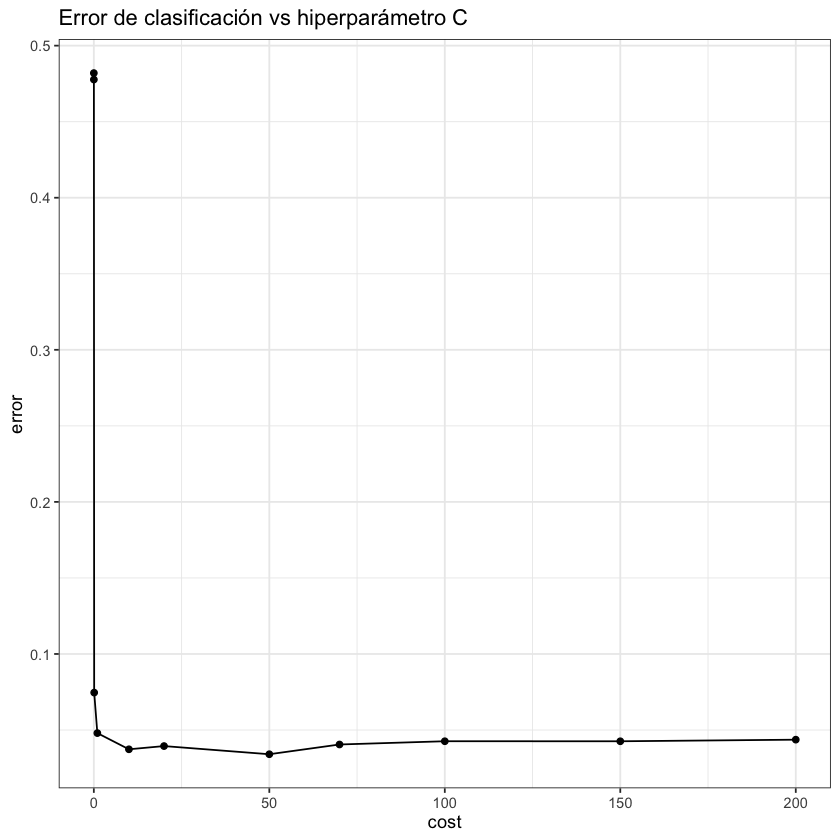

In [32]:
#veamos relacion entre errores y Costo:
ggplot(data = svm_cv.r$performances, aes(x = cost, y = error)) +
  geom_line() +
  geom_point() +
  labs(title = "Error de clasificación vs hiperparámetro C") +
  theme_bw()

In [33]:
svm_mejor.r <- svm_cv.r$best.model

In [34]:
#veamos la prediccion en test:
pred.svm_mejor.r <- predict(svm_mejor.r, testeo, type = "class") # da la clase predicha
tabla.svm_mejor.r <- table(pred.svm_mejor.r, testeo$Direction) 
confusion.svm_mejor.r <- confusionMatrix(tabla.svm_mejor.r, positive = "Up")
confusion.svm_mejor.r

Confusion Matrix and Statistics

                
pred.svm_mejor.r Down  Up
            Down  147   8
            Up      3 154
                                          
               Accuracy : 0.9647          
                 95% CI : (0.9378, 0.9823)
    No Information Rate : 0.5192          
    P-Value [Acc > NIR] : <2e-16          
                                          
                  Kappa : 0.9295          
                                          
 Mcnemar's Test P-Value : 0.2278          
                                          
            Sensitivity : 0.9506          
            Specificity : 0.9800          
         Pos Pred Value : 0.9809          
         Neg Pred Value : 0.9484          
             Prevalence : 0.5192          
         Detection Rate : 0.4936          
   Detection Prevalence : 0.5032          
      Balanced Accuracy : 0.9653          
                                          
       'Positive' Class : Up              
            

In [35]:
# El ajuste siempre será sobre los hiperparámetros del kernel y C
# para kernel radial el hiperparámetro es gamma

set.seed(123) 
svm_cv.r2 <- tune("svm", 
                  Direction~.-Year, 
                  data = entreno, 
                  probability = TRUE,
                  kernel = 'radial',
                  ranges = list(cost = c(0.001, 0.01, 0.1, 1, 10, 20, 50, 100),
                  gamma = c(0.0001,0.001,0.01, 1, 10))) #default: 1/(data dimension)
summary(svm_cv.r2)


Parameter tuning of ‘svm’:

- sampling method: 10-fold cross validation 

- best parameters:
 cost gamma
  100  0.01

- best performance: 0.009597346 

- Detailed performance results:
    cost gamma       error  dispersion
1  1e-03 1e-04 0.481960650 0.026755978
2  1e-02 1e-04 0.481960650 0.026755978
3  1e-01 1e-04 0.481960650 0.026755978
4  1e+00 1e-04 0.481960650 0.026755978
5  1e+01 1e-04 0.090619995 0.029961710
6  2e+01 1e-04 0.082075040 0.031514303
7  5e+01 1e-04 0.051166781 0.023472912
8  1e+02 1e-04 0.040505605 0.017246734
9  1e-03 1e-03 0.481960650 0.026755978
10 1e-02 1e-03 0.481960650 0.026755978
11 1e-01 1e-03 0.481960650 0.026755978
12 1e+00 1e-03 0.091683825 0.031568741
13 1e+01 1e-03 0.041569435 0.016984056
14 2e+01 1e-03 0.035186456 0.015949434
15 5e+01 1e-03 0.019171814 0.012082273
16 1e+02 1e-03 0.015980325 0.013513347
17 1e-03 1e-02 0.481960650 0.026755978
18 1e-02 1e-02 0.481960650 0.026755978
19 1e-01 1e-02 0.105559369 0.036520866
20 1e+00 1e-02 0.045824754 0.017400

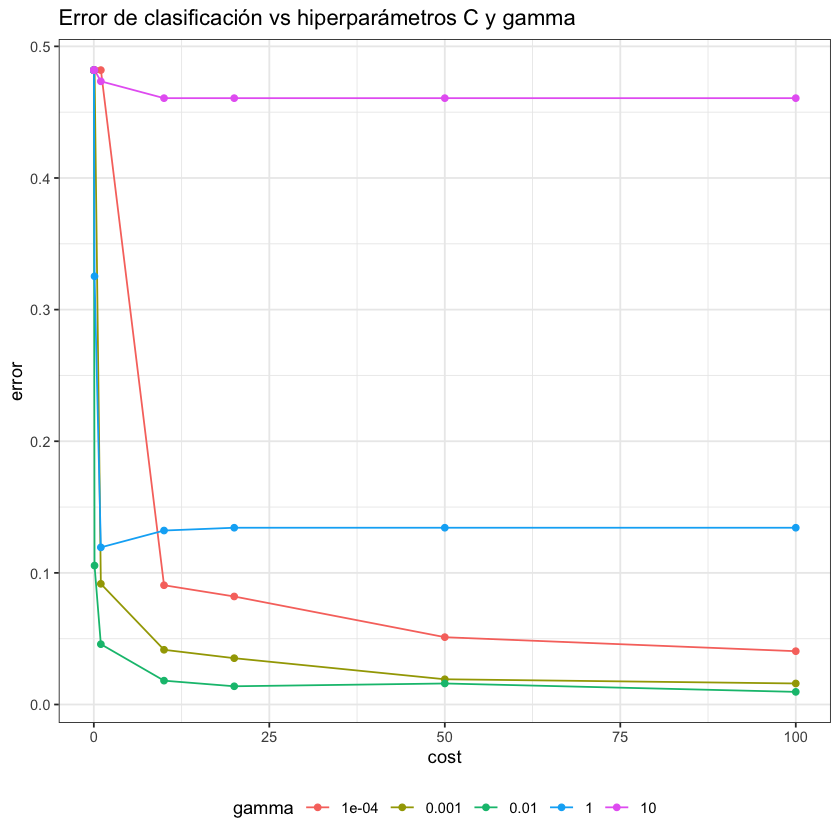

In [36]:
#veamos relacion entre errores Gamma y Costo
ggplot(data = svm_cv.r2$performances, aes(x = cost, y = error, color = as.factor(gamma))) +
  geom_line() +
  geom_point() +
  labs(title = "Error de clasificación vs hiperparámetros C y gamma", color = "gamma") +
  theme_bw() +
  theme(legend.position = "bottom")

* gamma grande es el peor (color violeta)
* gamma chico (color verde)

In [37]:
names(svm_cv.r2)
svm_cv.r2$best.model$gamma
svm_mejor.r2 <- svm_cv.r2$best.model

[1] "best.parameters"  "best.performance" "method"           "nparcomb"        
[5] "train.ind"        "sampling"         "performances"     "best.model"

[1] 0.01

In [38]:
# Prediccion en test:
pred.svm_mejor.r2 <- predict(svm_mejor.r2, testeo, type = "class")# da la clase predicha
tabla.svm_mejor.r2 <- table(pred.svm_mejor.r2, testeo$Direction) 
confusion.svm_mejor.r2 <- confusionMatrix(tabla.svm_mejor.r2, positive = "Up")
confusion.svm_mejor.r2

Confusion Matrix and Statistics

                 
pred.svm_mejor.r2 Down  Up
             Down  148   3
             Up      2 159
                                         
               Accuracy : 0.984          
                 95% CI : (0.963, 0.9948)
    No Information Rate : 0.5192         
    P-Value [Acc > NIR] : <2e-16         
                                         
                  Kappa : 0.9679         
                                         
 Mcnemar's Test P-Value : 1              
                                         
            Sensitivity : 0.9815         
            Specificity : 0.9867         
         Pos Pred Value : 0.9876         
         Neg Pred Value : 0.9801         
             Prevalence : 0.5192         
         Detection Rate : 0.5096         
   Detection Prevalence : 0.5160         
      Balanced Accuracy : 0.9841         
                                         
       'Positive' Class : Up             
                            

In [39]:
# Se evalua la capacidad predictiva con el area bajo ROC
# hay que darle la prediccion como probabilidades!
pred.svm2 <- predict(svm_mejor.r2, testeo, type = "prob", probability = TRUE)
pred.svm2

1    3    7    8    9   11   14   18   21   26   29   31   33   45   51   54 
  Up Down Down   Up   Up Down   Up   Up Down   Up Down Down Down   Up   Up Down 
  65   66   75   77   84   88   92   94   99  105  109  111  114  116  119  123 
  Up Down   Up   Up   Up   Up Down   Up   Up Down Down   Up Down Down Down Down 
 124  127  129  132  134  137  138  151  152  157  162  170  173  179  180  182 
  Up   Up Down   Up Down   Up   Up Down   Up Down Down Down Down Down   Up Down 
 184  188  189  197  205  206  212  230  235  238  240  241  243  253  256  263 
Down Down Down   Up   Up Down   Up Down   Up Down   Up   Up   Up Down Down   Up 
 266  268  272  273  276  279  282  283  287  289  290  303  306  310  321  323 
Down Down   Up Down   Up   Up Down   Up Down   Up Down Down   Up   Up Down Down 
 342  343  344  351  352  365  373  376  380  382  385  393  395  397  409  412 
Down Down Down Down   Up   Up Down Down Down Down   Up   Up Down Down Down   Up 
 415  416  422  423  429  432  439  446  450  451  452  455  457  460  463  468 
  Up   Up Down Down Down Down   Up Down Down Down   Up   Up   Up Down   Up   Up 
 471  475  476  477  480  485  486  491  493  497  501  507  510  511  516  520 
Down Down Down Down   Up Down Down Down   Up   Up Down Down Down Down   Up Down 
 521  524  533  545  546  557  559  560  567  569  571  574  576  582  583  584 
  Up Down   Up   Up   Up   Up   Up   Up Down Down   Up   Up Down Down   Up   Up 
 585  591  592  600  601  602  607  608  609  611  620  623  625  631  641  649 
Down   Up   Up   Up   Up Down Down   Up   Up Down   Up   Up Down   Up Down Down 
 653  656  659  666  670  678  679  688  691  692  693  694  697  700  719  720 
  Up Down   Up   Up   Up Down Down Down   Up   Up Down   Up   Up Down Down   Up 
 725  730  731  735  736  738  739  741  749  753  754  764  766  772  779  786 
  Up   Up Down Down   Up   Up Down   Up   Up   Up Down Down Down Down Down   Up 
 791  794  795  796  800  806  813  815  816  818  819  822  828  831  837  841 
Down Down   Up Down Down   Up Down   Up Down   Up   Up   Up Down   Up   Up   Up 
 846  857  859  863  867  872  881  882  883  893  896  897  900  908  915  917 
  Up   Up   Up Down Down Down Down Down   Up Down Down   Up Down   Up   Up   Up 
 918  925  926  936  939  943  944  945  946  948  949  955  962  964  967  969 
Down   Up Down   Up Down Down Down   Up   Up   Up   Up   Up Down   Up Down   Up 
 970  974  976  988  994 1009 1010 1015 1019 1022 1024 1029 1033 1036 1046 1048 
Down   Up Down Down Down   Up Down   Up   Up   Up   Up   Up Down   Up Down Down 
1049 1051 1058 1059 1063 1074 1076 1085 1091 1093 1094 1099 1102 1112 1120 1121 
Down Down   Up Down   Up   Up   Up Down   Up   Up   Up   Up   Up   Up Down   Up 
1124 1128 1134 1135 1137 1138 1139 1140 1143 1144 1145 1155 1160 1163 1180 1184 
  Up   Up Down   Up Down   Up Down   Up Down   Up   Up Down Down Down Down   Up 
1187 1194 1199 1202 1203 1204 1207 1208 1210 1211 1221 1224 1225 1227 1231 1232 
  Up Down Down   Up   Up Down   Up   Up   Up   Up   Up   Up   Up Down   Up Down 
1233 1238 1239 1241 1243 1247 1248 1250 
  Up   Up   Up Down   Up Down   Up Down 
attr(,"probabilities")
               Up         Down
1    9.999990e-01 9.632098e-07
3    2.466320e-06 9.999975e-01
7    1.778191e-04 9.998222e-01
8    7.636760e-01 2.363240e-01
9    9.999999e-01 1.000000e-07
11   4.315522e-05 9.999568e-01
14   9.999997e-01 2.636224e-07
18   9.996317e-01 3.683390e-04
21   2.213885e-06 9.999978e-01
26   9.999999e-01 1.000000e-07
29   1.000000e-07 9.999999e-01
31   2.267730e-06 9.999977e-01
33   3.460397e-07 9.999997e-01
45   9.996958e-01 3.042250e-04
51   9.999999e-01 1.000000e-07
54   1.000000e-07 9.999999e-01
65   9.999999e-01 1.000000e-07
66   2.006851e-03 9.979931e-01
75   9.999999e-01 1.000000e-07
77   9.999999e-01 1.000000e-07
84   5.212885e-01 4.787115e-01
88   9.999999e-01 1.000000e-07
92   1.957535e-02 9.804246e-01
94   9.990651e-01 9.349334e-04
99   9.993793e-01 6.206951e-04
105  3.287669e

In [40]:
pred.svm2.prob <- attr(pred.svm2, "probabilities")[,1] # para extraer probab de "Up"
head(pred.svm2.prob)

1            3            7            8            9           11 
9.999990e-01 2.466320e-06 1.778191e-04 7.636760e-01 9.999999e-01 4.315522e-05

In [41]:
pred_svm_rad2 <- prediction(pred.svm2.prob, testeo$Direction)
perf_svm_rad2 <- performance(pred_svm_rad2, "tpr", "fpr")

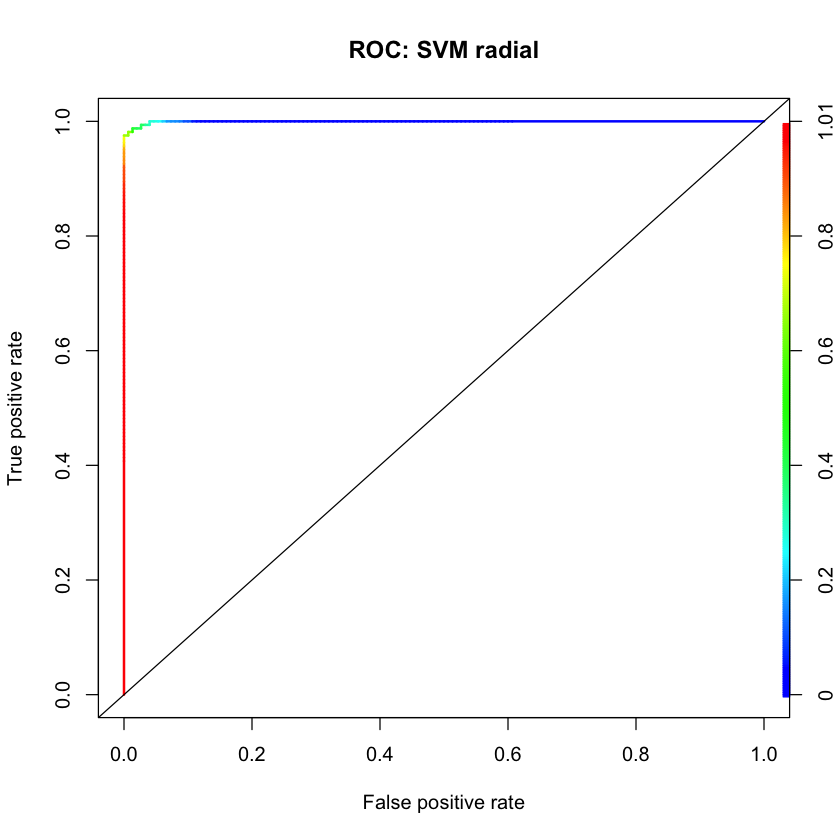

In [42]:
plot(perf_svm_rad2, lwd=2, colorize=TRUE, main="ROC: SVM radial")
abline(a = 0, b = 1)

In [43]:
AUC.svm_rad2 <- performance(pred_svm_rad2, "auc")@y.values   #para que me de AUC
AUC.svm_rad2

[[1]]
[1] 0.999465

In [44]:
metricas_SVM <- data.frame(
  Model = "Modelo SVM radial",
  Accuracy = confusion.svm_mejor.r2$overall["Accuracy"],
  Sensitivity = confusion.svm_mejor.r2$byClass["Sensitivity"],
  Specificity = confusion.svm_mejor.r2$byClass["Specificity"],
  Precision = confusion.svm_mejor.r2$byClass["Pos Pred Value"],
  Area_ROC = AUC.svm_rad2[[1]])
metricas_SVM

,Model,Accuracy,Sensitivity,Specificity,Precision,Area_ROC
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Accuracy,Modelo SVM radial,0.9839744,0.9814815,0.9866667,0.9875776,0.999465
